# 3. 3D reconstruction from Hi-C data

U-Chrom provides several 3D reconstruction algorithms:

| Module | Best for | Notes |
|--------|---------|-------|
| `uchrom.recon.sc.nucdyn` | Single-cell Hi-C / Dip-C | Molecular-dynamics, Taichi GPU |
| `uchrom.recon.sc.gem` | Single-cell, energy minimisation | Taichi autodiff |
| `uchrom.recon.bulk.mds` | Bulk Hi-C | SMACOF MDS, PyTorch GPU |

This notebook walks through a short single-cell reconstruction using Nuc
Dynamics on the example data shipped with the repo.


## Locate the example data

The notebook looks for `example-data/cell1.pairs` in the repo; we walk up the directory tree to find the repo root so this runs from any cwd.


In [1]:
from pathlib import Path

def find_repo_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / 'example-data' / 'cell1.pairs').exists():
            return p
    raise FileNotFoundError('Could not locate example-data/cell1.pairs')

repo = find_repo_root()
pairs = repo / 'example-data' / 'cell1.pairs'
out_path = repo / 'tutorials' / '_out_tutorial3.h5cd'
print('pairs:', pairs)
print('out  :', out_path)


pairs: /Users/weizexu/Projects/U-Chrom/example-data/cell1.pairs
out  : /Users/weizexu/Projects/U-Chrom/tutorials/_out_tutorial3.h5cd


## Run Nuc Dynamics

The CLI is the simplest way; the main function is also importable.


In [2]:
# From the shell (uncomment to run):
# !python -m uchrom.recon.sc.nucdyn example-data/cell1.pairs out.h5cd \
#     --arch=cpu --dyns=30 --size_steps='[2, 0.4]'

from uchrom.recon.sc.nucdyn import main as nucdyn_main
nucdyn_main(
    str(pairs),
    str(out_path),
    arch='cpu',      # 'cuda' if you have an NVIDIA GPU
    dyns=30,         # fewer steps for the tutorial
    size_steps=[2, 0.4],  # only two resolution stages
)


[Taichi] version 1.7.4, llvm 15.0.7, commit b4b956fd, osx, python 3.11.15


[I 04/22/26 16:25:12.143 43886106] [shell.py:_shell_pop_print@23] Graphical python shell detected, using wrapped sys.stdout


/Users/weizexu/Projects/U-Chrom/example-data/cell1.pairs
Loading data
num_pixels:105700
{'genome_ranges': None, 'pow': -0.33, 'bb_lower': 0.1, 'bb_upper': 1.1, 'lower': 0.8, 'upper': 1.2, 'scale': 1.0, 'repulsive_lim': 2.0, 'hot': 5000.0, 'cold': 10.0, 'dyns': 30, 'random_seed': 0, 'time_step': 0.01, 'size_steps': [2, 0.4], 'max_radius': 10.0, 'use_grid': False, 'grid_range_scale': 5.0, 'cell_capacity': 10000, 'shift_freq': 10, 'min_skip': 2, 'violated_threshold': 5.0}
[Taichi] Starting on arch=arm64


particle_size:2000000 num_particles:1275
num_contact:6124 num_restraints:7379
-------------------- step:0
total_force:1997017.208984375 temp:5000.0 c_temp:0.0010000000474974513 k1:0.18169011381620936 repulsive:4170.458984375 restraint:1992846.75 rmsd:13.304428100585938 rsmd_backbone:5.395815 rsmd_contact:12.161126
-------------------- step:1
total_force:1887507.35546875 temp:4064.473885463579 c_temp:7540.4287109375 k1:0.18321921453359458 repulsive:4454.23046875 restraint:1883053.125 rmsd:12.586146354675293 rsmd_backbone:5.137711 rsmd_contact:11.489778
-------------------- step:2
total_force:1713659.5478515625 temp:3303.98959312308 c_temp:10837.81640625 k1:0.18498067917599081 repulsive:4766.6728515625 restraint:1708892.875 rmsd:11.455716133117676 rsmd_backbone:4.7284856 rsmd_contact:10.434312
-------------------- step:3
total_force:1486745.4306640625 temp:2685.7958838184386 c_temp:13642.2353515625 k1:0.1870315310618138 repulsive:5069.6806640625 restraint:1481675.75 rmsd:9.99913501739502

particle_size:400000 num_particles:6406
num_contact:10861 num_restraints:17247
-------------------- step:0
total_force:708647.9921875 temp:5000.0 c_temp:0.0010000000474974513 k1:0.18169011381620936 repulsive:99471.5546875 restraint:609176.4375 rmsd:2.1069579124450684 rsmd_backbone:0.3705961 rsmd_contact:2.0741096
-------------------- step:1
total_force:700145.265625 temp:4064.473885463579 c_temp:501.7908935546875 k1:0.18321921453359458 repulsive:101747.390625 restraint:598397.875 rmsd:2.0741357803344727 rsmd_backbone:0.36923742 rsmd_contact:2.0410054
-------------------- step:2
total_force:685805.1640625 temp:3303.98959312308 c_temp:774.6554565429688 k1:0.18498067917599081 repulsive:105194.1640625 restraint:580611.0 rmsd:2.020024538040161 rsmd_backbone:0.36728024 rsmd_contact:1.9863546
-------------------- step:3
total_force:666472.4921875 temp:2685.7958838184386 c_temp:1034.2357177734375 k1:0.1870315310618138 repulsive:109880.8671875 restraint:556591.625 rmsd:1.9470914602279663 rsmd_b

-------------------- step:10
total_force:498394.625 temp:629.9605249474369 c_temp:2346.44482421875 k1:0.22318757369920827 repulsive:190317.8125 restraint:308076.8125 rmsd:1.2182093858718872 rsmd_backbone:0.3969851 rsmd_contact:1.1517104
-------------------- step:11
total_force:491753.09375 temp:512.0916205043567 c_temp:2464.957275390625 k1:0.23775236811945244 repulsive:213723.65625 restraint:278029.4375 rmsd:1.1361205577850342 rsmd_backbone:0.4127732 rsmd_contact:1.0584838
-------------------- step:12
total_force:499472.421875 temp:416.27660370093656 c_temp:2572.534912109375 k1:0.26044473331224577 repulsive:245388.234375 restraint:254084.1875 rmsd:1.071772813796997 rsmd_backbone:0.43137524 rsmd_contact:0.9811281
-------------------- step:13
total_force:530657.09375 temp:338.38907697438566 c_temp:2669.403564453125 k1:0.2993598785091408 repulsive:293494.21875 restraint:237162.875 rmsd:1.027066946029663 rsmd_backbone:0.4523739 rsmd_contact:0.9220761
-------------------- step:14
total_forc

-------------------- step:26
total_force:1038251.53125 temp:22.901433483115337 c_temp:3838.314453125 k1:0.8105510125100134 repulsive:629147.0 restraint:409104.53125 rmsd:1.4809576272964478 rsmd_backbone:0.7224474 rsmd_contact:1.2927897
-------------------- step:27
total_force:1029231.1875 temp:18.616455666360697 c_temp:3949.5380859375 k1:0.8129684689381862 repulsive:610521.9375 restraint:418709.25 rmsd:1.5024867057800293 rsmd_backbone:0.7289752 rsmd_contact:1.3137965
-------------------- step:28
total_force:1018256.96875 temp:15.133219579162699 c_temp:4064.757080078125 k1:0.8150193208240092 repulsive:593519.1875 restraint:424737.78125 rmsd:1.5144637823104858 rsmd_backbone:0.7326594 rsmd_contact:1.3254474
-------------------- step:29
total_force:1005340.125 temp:12.301715156498592 c_temp:4183.619140625 k1:0.8167807854664054 repulsive:578075.4375 restraint:427264.6875 rmsd:1.5172784328460693 rsmd_backbone:0.7336893 rsmd_contact:1.328094


## Load the reconstructed structure

The `.h5cd` output carries a `cell_id` derived from the filename and one trace per chromosome.


In [3]:
from uchrom import ChromData
cd = ChromData.read(str(out_path))
cd


ChromData: n_spots=6406, n_traces=20, n_cells=1
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'contact_count']

In [4]:
print('chroms  :', cd.chroms)
print('n_spots :', cd.n_spots)
cd.spots.head()


chroms  : ['chr1', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chrX']
n_spots : 6406


,chrom,start,end,trace_id,cell_id,contact_count
0,chr1,3018338,3419030,0,_out_tutorial3,1
1,chr1,3419030,3819723,0,_out_tutorial3,0
2,chr1,3819723,4220415,0,_out_tutorial3,1
3,chr1,4220415,4621108,0,_out_tutorial3,3
4,chr1,4621108,5021800,0,_out_tutorial3,4


## Compute a distance matrix for one chromosome


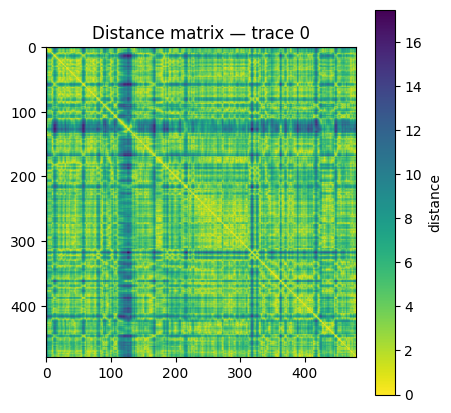

In [5]:
import matplotlib.pyplot as plt

trace_id = cd.spots['trace_id'].iloc[0]
D = cd.compute_distances(trace_id=trace_id)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(D, cmap='viridis_r', aspect='equal')
ax.set_title(f'Distance matrix — trace {trace_id}')
fig.colorbar(im, ax=ax, label='distance')


## Using other reconstruction backends

`python -m uchrom.recon.sc.gem <in> <out.h5cd>` — energy-minimisation
variant (smoother, slower).

`python -m uchrom.recon.bulk.mds <contact.mcool> <out.h5cd> --resolution=100000`
— PyTorch SMACOF MDS on bulk Hi-C data.  Inter-chromosomal whole-genome
reconstruction via `--inter` with the additional `--resolution_inter` flag.

All three write the same `.h5cd` schema so downstream tools don't care
which reconstructor was used.
